<a href="https://colab.research.google.com/github/ayushsharma0130/Statistics-Practicals/blob/main/Stats_Assig_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/evalsdataset.csv")

In [ ]:
print("First 5 rows of the dataset:")
print(df.head())

First 5 rows of the dataset:
   course_id  prof_id  score          rank     ethnicity  gender language  \
0          1        1    4.7  tenure track      minority  female  english   
1          2        1    4.1  tenure track      minority  female  english   
2          3        1    3.9  tenure track      minority  female  english   
3          4        1    4.8  tenure track      minority  female  english   
4          5        2    4.6       tenured  not minority    male  english   

   age  cls_perc_eval  cls_did_eval  ...   cls_credits bty_f1lower  \
0   36       55.81395            24  ...  multi credit           5   
1   36       68.80000            86  ...  multi credit           5   
2   36       60.80000            76  ...  multi credit           5   
3   36       62.60163            77  ...  multi credit           5   
4   59       85.00000            17  ...  multi credit           4   

  bty_f1upper bty_f2upper  bty_m1lower  bty_m1upper  bty_m2upper  bty_avg  \
0         

In [ ]:
print("\nColumn names:")
print(df.columns)


Column names:
Index(['course_id', 'prof_id', 'score', 'rank', 'ethnicity', 'gender',
       'language', 'age', 'cls_perc_eval', 'cls_did_eval', 'cls_students',
       'cls_level', 'cls_profs', 'cls_credits', 'bty_f1lower', 'bty_f1upper',
       'bty_f2upper', 'bty_m1lower', 'bty_m1upper', 'bty_m2upper', 'bty_avg',
       'pic_outfit', 'pic_color'],
      dtype='object')


##**Q1. Calculate the percentage of visible minorities are tenure professors. Will you say that tenure status differed if teacher was a visible minority?**

In [ ]:
minority = df[df["ethnicity"] == "minority"]

In [ ]:
tenured_minority = minority[minority["rank"] == "tenured"]

In [ ]:
percentage = (len(tenured_minority) / len(minority)) * 100

print("Total minority professors:", len(minority))
print("Tenured minority professors:", len(tenured_minority))
print("Percentage of minority professors who are tenured:",
      round(percentage, 2), "%")

Total minority professors: 64
Tenured minority professors: 26
Percentage of minority professors who are tenured: 40.62 %


In [ ]:
print("\nTenure distribution by ethnicity:")
print(
    pd.crosstab(
        df["ethnicity"],
        df["rank"],
        normalize="index"
    ) * 100
)


Tenure distribution by ethnicity:
rank           teaching  tenure track    tenured
ethnicity                                       
minority      15.625000     43.750000  40.625000
not minority  23.057644     20.050125  56.892231


##**Q2. Does average age differ by tenure? Produce the means and standard deviations for both tenured and untenured professors.**

In [ ]:
df["Tenure_Status"] = df["rank"].apply(
    lambda x: "Tenured" if x == "tenured" else "Untenured"
)

In [ ]:
age_statistics = df.groupby("Tenure_Status")["age"].agg(
    ["mean", "std"]
)

print(age_statistics)

print("\nMean and Standard Deviation:")
for status, row in age_statistics.iterrows():
    print(
        status,
        "Mean Age =", round(row["mean"], 2),
        "Standard Deviation =", round(row["std"], 2)
    )

                    mean       std
Tenure_Status                     
Tenured        51.889328  8.654502
Untenured      44.119048  9.431705

Mean and Standard Deviation:
Tenured Mean Age = 51.89 Standard Deviation = 8.65
Untenured Mean Age = 44.12 Standard Deviation = 9.43


##**Q3. Which graph works better and plot that graph for the age variable?**

Histogram is suitable for the age variable.


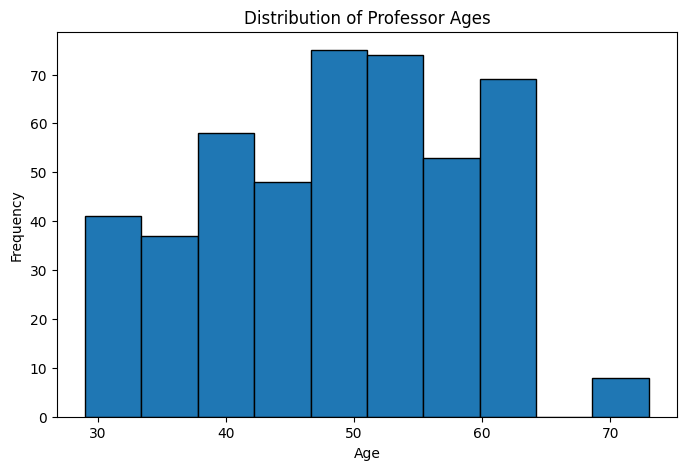

In [ ]:
print("Histogram is suitable for the age variable.")

plt.figure(figsize=(8, 5))

plt.hist(
    df["age"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Professor Ages")

plt.show()

##**4. Define the difference between pyplot.bar and pyplot.barh. Also plot the graph for gender variable.**


plt.bar() creates a vertical bar graph.
plt.barh() creates a horizontal bar graph.

plt.bar():
    Categories -> X-axis
    Values     -> Y-axis

plt.barh():
    Categories -> Y-axis
    Values     -> X-axis

Gender counts:
gender
male      268
female    195
Name: count, dtype: int64


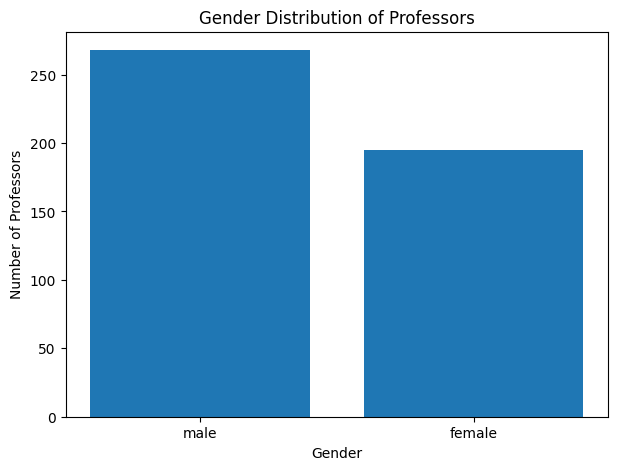

In [ ]:
print("""
plt.bar() creates a vertical bar graph.
plt.barh() creates a horizontal bar graph.

plt.bar():
    Categories -> X-axis
    Values     -> Y-axis

plt.barh():
    Categories -> Y-axis
    Values     -> X-axis
""")

# Count gender
gender_counts = df["gender"].value_counts()

print("Gender counts:")
print(gender_counts)

# Plot gender graph
plt.figure(figsize=(7, 5))

plt.bar(
    gender_counts.index,
    gender_counts.values
)
plt.xlabel("Gender")
plt.ylabel("Number of Professors")
plt.title("Gender Distribution of Professors")

plt.show()


##**5. What is the Median evaluation score for tenured Professors?**

In [ ]:
tenured = df[df["rank"] == "tenured"]

median_score = tenured["score"].median()
print(
    "Median evaluation score for tenured professors:",
    median_score
)

Median evaluation score for tenured professors: 4.2


##**TheMedian evaluation score for tenured professors: 4.2**